# Lab Assessment 9: Principal Component Analysis
**School of Computer Science and Engineering** | BCSE331P - Exploratory Data Analysis | Fall Semester 2026-27

Dataset: **BEPS**. R `PCA()/prcomp`, `ggplot2`, `ggfortify`, `FactoMineR`, `factoextra` -> `sklearn.decomposition.PCA`, `matplotlib`, `seaborn`, `adjustText`.

In [1]:
!pip install -q adjustText

## 1. Load the dataset and verify the packages

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from IPython.display import display

try:
    from adjustText import adjust_text          # non-overlapping labels (like ggrepel)
    print("adjustText loaded")
except ImportError:
    adjust_text = None
    print("adjustText not available - labels may overlap")

# verify the packages that replace ggplot2 / ggfortify / FactoMineR / factoextra
print("matplotlib", matplotlib.__version__, "| seaborn", sns.__version__,
      "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

REG_NO = "23BCE1234"     # <-- change to YOUR registration number
sns.set_theme(style="whitegrid")

adjustText loaded
matplotlib 3.10.0 | seaborn 0.13.2 | scikit-learn 1.6.1 | pandas 2.2.3


In [3]:
URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/BEPS.csv"
df = pd.read_csv(URL)

# BEPS has an unnamed row-index column -> drop it; replace '.' in names with '_' (easier in Python)
df = df.loc[:, ~df.columns.str.match(r"^(Unnamed.*|X|rownames)$")]
df.columns = df.columns.str.replace(".", "_", regex=False)
print("Shape:", df.shape)
df.head()

Shape: (1525, 10)


,vote,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge,gender
0,Liberal Democrat,43,3,3,4,1,4,2,2,female
1,Labour,36,4,4,4,4,4,5,2,male
2,Labour,35,4,4,5,2,3,3,2,male
3,Labour,24,4,2,2,1,3,4,0,female
4,Labour,41,2,2,1,1,4,6,2,male


## 2. Total number of rows and columns

In [4]:
print("Rows   :", df.shape[0])
print("Columns:", df.shape[1])

Rows   : 1525
Columns: 10


## 3. Extract numeric columns, clean, and normalize with `scale()` -> `data_scaled`

In [5]:
data_num = df.select_dtypes(include="number").dropna()        # numeric columns only + remove NaN rows
print("Numeric columns:", data_num.columns.tolist(), "| shape:", data_num.shape)

data_scaled = pd.DataFrame(StandardScaler().fit_transform(data_num), columns=data_num.columns)
display(data_scaled.describe().loc[["mean", "std"]].round(3))

Numeric columns: ['age', 'economic_cond_national', 'economic_cond_household', 'Blair', 'Hague', 'Kennedy', 'Europe', 'political_knowledge'] | shape: (1525, 8)


,age,economic_cond_national,economic_cond_household,Blair,Hague,Kennedy,Europe,political_knowledge
mean,0.0,-0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 4. Principal Component Analysis and its summary

In [6]:
pca = PCA()
pca_result = pca.fit(data_scaled)

n_pc = len(pca.explained_variance_)
pc_names = [f"PC{i+1}" for i in range(n_pc)]

summary = pd.DataFrame({
    "Standard deviation":     np.sqrt(pca.explained_variance_),
    "Proportion of Variance": pca.explained_variance_ratio_,
    "Cumulative Proportion":  np.cumsum(pca.explained_variance_ratio_),
}, index=pc_names).T.round(4)
print("Importance of components:")
display(summary)

print("Loadings (rotation):")
loadings = pd.DataFrame(pca.components_.T, index=data_scaled.columns, columns=pc_names).round(3)
display(loadings)

Importance of components:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
Standard deviation,1.4147,1.0787,1.0094,0.9751,0.9473,0.8476,0.8004,0.7836
Proportion of Variance,0.2500,0.1453,0.1273,0.1188,0.1121,0.0897,0.0800,0.0767
Cumulative Proportion,0.2500,0.3954,0.5226,0.6414,0.7535,0.8433,0.9233,1.0000


Loadings (rotation):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
age,-0.037,-0.373,0.690,-0.572,0.112,-0.107,-0.179,-0.029
economic_cond_national,0.477,-0.280,-0.152,-0.118,0.190,-0.061,0.318,0.718
economic_cond_household,0.370,-0.353,-0.441,-0.061,0.361,-0.265,-0.391,-0.432
Blair,0.490,-0.097,0.149,-0.025,-0.086,0.547,0.451,-0.466
Hague,-0.397,-0.219,-0.106,0.062,0.567,0.652,-0.127,0.128
Kennedy,0.213,0.032,0.516,0.712,0.377,-0.184,-0.055,0.006
Europe,-0.434,-0.401,-0.081,0.093,0.136,-0.367,0.656,-0.227
political_knowledge,0.045,0.663,0.001,-0.366,0.575,-0.146,0.249,-0.107


## 5. Scree plot - % variance per component with data labels (y-axis 0-60)

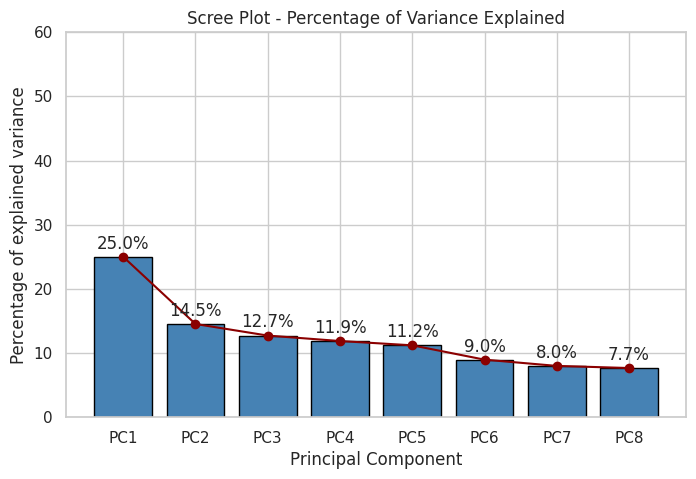

In [7]:
var_pct = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(pc_names, var_pct, color="steelblue", edgecolor="black")
ax.plot(pc_names, var_pct, "o-", color="darkred")
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in var_pct], padding=3)
ax.set_ylim(0, 60)
ax.set_title("Scree Plot - Percentage of Variance Explained")
ax.set_xlabel("Principal Component")
ax.set_ylabel("Percentage of explained variance")
plt.show()

## 6. PCA biplot with non-overlapping labels and a proper title

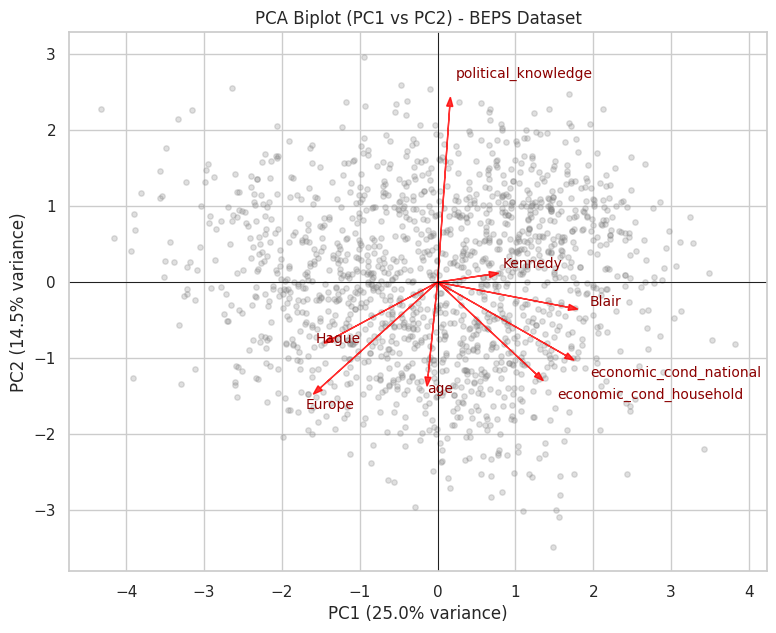

In [8]:
scores = pca.transform(data_scaled)
load = pca.components_[:2].T                              # loadings of PC1, PC2
scale_f = np.abs(scores[:, :2]).max() * 0.85              # stretch arrows to the score range

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(scores[:, 0], scores[:, 1], alpha=0.25, color="grey", s=15)

texts = []
for i, var in enumerate(data_scaled.columns):
    ax.arrow(0, 0, load[i, 0] * scale_f, load[i, 1] * scale_f, color="red", head_width=0.08, alpha=0.8,
             length_includes_head=True)
    texts.append(ax.text(load[i, 0] * scale_f * 1.08, load[i, 1] * scale_f * 1.08, var,
                         color="darkred", fontsize=10))
if adjust_text is not None:
    adjust_text(texts, ax=ax)

ax.axhline(0, color="black", lw=0.6)
ax.axvline(0, color="black", lw=0.6)
ax.set_title("PCA Biplot (PC1 vs PC2) - BEPS Dataset")
ax.set_xlabel(f"PC1 ({var_pct[0]:.1f}% variance)")
ax.set_ylabel(f"PC2 ({var_pct[1]:.1f}% variance)")
plt.show()

## 7. PCA scores in a data frame `pca_scores` (first six rows)

In [9]:
pca_scores = pd.DataFrame(scores, columns=pc_names)
pca_scores.head(6)

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
0,1.490955,1.533956,0.383593,0.628420,-0.692711,-0.163992,-0.346216,-0.275473
1,1.084228,0.104403,-0.904389,0.919927,1.369365,0.784181,-0.039218,0.194475
2,2.215290,0.615058,-1.076145,0.118445,-0.064936,0.589664,0.216133,-0.277043
3,0.301491,0.714245,-0.930227,1.368556,-2.182520,-0.534788,-0.126994,1.887296
4,-1.223565,2.038242,0.463022,1.078803,-0.926369,-1.639023,-0.620026,0.292571
5,0.253474,0.222951,-1.178959,-0.692298,0.492732,1.229844,-0.621956,-0.583516


## 8. Scatter plot of PC1 vs PC2

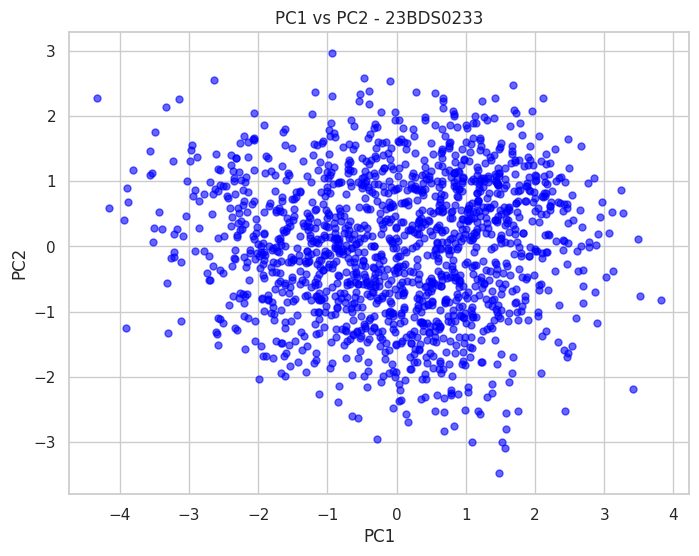

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(pca_scores["PC1"], pca_scores["PC2"], color="blue", marker="o", alpha=0.6, s=25)
ax.set_title(f"PC1 vs PC2 - 23BDS0233")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
plt.show()